# NYC Yellow Taxi — Trip Duration: Data and Features (January 2025)

**Goal:** predict the duration of a yellow-taxi trip using only what is known at pickup time: pickup
zone, drop-off zone and pickup time.

**This notebook covers the data and the features only:** the raw-data checks behind the cleaning rule,
the time-based split, the time patterns behind the features, and the features shared with the API. It
trains nothing and needs no MLflow server.

| Split | Pickup dates | Used for |
|---|---|---|
| Train | Jan 1–20 | fitting every model and all learned statistics |
| Validation | Jan 21–25 | comparing models |
| Test | Jan 26–31 | one final evaluation of the selected model |

The models (baselines, Optuna search, selection) are produced by `uv run nyc-taxi all`. How the served
model was chosen, with its validation and test results, is shown in `model_serving_selection.ipynb`.

**Before running:** nothing else is needed; the January file and the TLC zone shapefile are downloaded
into `data/` on first use.

## 1. Setup

In [3]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from src import evaluation as ev
from src.features import FEATURES, build_features, build_zone_xy
from src.train import COLUMNS, DATA_PATH, DATA_URL, clean_trips, download_january, split_by_time

ModuleNotFoundError: No module named 'holidays'

## 1.1 Raw data check: why trips are filtered

Before cleaning, look at the raw January file (all records, no filter) to justify the rule in
`src.train.clean_trips`: **keep trips of 1-60 minutes**. `trip_distance` and the fare columns are loaded
here only for these checks; they are not model features (they are only known after the trip).

In [4]:
MIN_DURATION_MINUTES, MAX_DURATION_MINUTES = 1, 60  # same rule as src.train.clean_trips
MAX_DISTANCE_MILES = 100  # a NYC yellow-taxi trip longer than this is not plausible
TARGET = "duration"
BLUE, ORANGE = "#1f77b4", "#ff7f0e"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

# Columns for these checks only. The training download keeps 4 columns, so if the local file
# does not have them they are read from the TLC URL instead (~1 min, not saved).
CHECK_COLUMNS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
                 "fare_amount", "tip_amount", "total_amount"]
if not DATA_PATH.exists():
    download_january()  # one-time download, ~1 min
has_columns = set(CHECK_COLUMNS) <= set(pq.read_schema(DATA_PATH).names)
trips = pd.read_parquet(DATA_PATH if has_columns else DATA_URL, columns=CHECK_COLUMNS)

trips[TARGET] = (
    trips["tpep_dropoff_datetime"] - trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60
trips["speed_mph"] = trips["trip_distance"] / (trips[TARGET] / 60)  # implied average speed
print(f"Raw records: {len(trips):,}")

Raw records: 3,475,226


### Duration

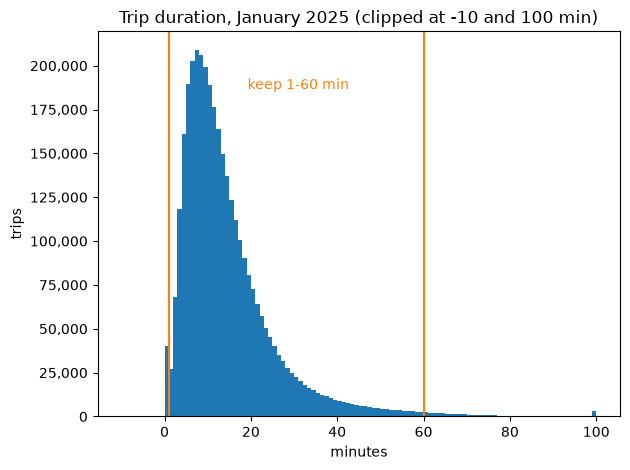

In [5]:
fig, ax = plt.subplots()
trips[TARGET].clip(-10, 100).plot.hist(
    bins=110, ax=ax, color=BLUE, edgecolor="none"
)
for bound in (MIN_DURATION_MINUTES, MAX_DURATION_MINUTES):
    ax.axvline(bound, color=ORANGE, linewidth=1.5)
ax.set(
    title="Trip duration, January 2025 (clipped at -10 and 100 min)",
    xlabel="minutes",
    ylabel="trips",
)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.annotate(
    "keep 1-60 min", xy=(31, ax.get_ylim()[1] * 0.85), color=ORANGE, ha="center"
)
fig.tight_layout()
fig.savefig(IMAGES / "duration_histogram.png")
plt.show()

In [6]:
share_kept = (
    trips[TARGET]
    .between(MIN_DURATION_MINUTES, MAX_DURATION_MINUTES)
    .mean()
)
print(f"Trips between 1 and 60 minutes: {share_kept:.1%}")

Trips between 1 and 60 minutes: 97.9%


What is in the removed tails? For each duration band: how many trips, the median distance, the share
with zero distance and the median implied speed (distance / duration).

In [7]:
bands = pd.cut(
    trips[TARGET],
    [-np.inf, 0, 1, 60, 180, 24 * 60, np.inf],
    right=False,
    labels=["< 0 min", "0-1 min", "1-60 min (kept)", "1-3 h", "3-24 h", ">= 24 h"],
)
by_band = trips.groupby(bands, observed=True).agg(
    trips=(TARGET, "size"),
    median_miles=("trip_distance", "median"),
    zero_distance=("trip_distance", lambda s: (s == 0).mean()),
    median_mph=("speed_mph", "median"),
)
by_band.insert(1, "share", by_band["trips"] / len(trips))
by_band.style.format({"trips": "{:,}", "share": "{:.2%}", "median_miles": "{:.2f}",
                      "zero_distance": "{:.1%}", "median_mph": "{:,.1f}"})

,trips,share,median_miles,zero_distance,median_mph
duration,,,,,
< 0 min,124,0.00%,4.67,0.0%,-857.0
0-1 min,"39,987",1.15%,0.00,66.3%,0.0
1-60 min (kept),"3,403,196",97.93%,1.68,1.9%,9.5
1-3 h,"30,542",0.88%,17.35,1.1%,14.7
3-24 h,"1,357",0.04%,2.37,1.8%,0.1
>= 24 h,20,0.00%,1.26,25.0%,0.0


- **Negative duration:** drop-off before pickup, a clock error. These cannot be a valid target.
- **Under 1 minute:** most have zero distance: cancelled rides, meter tests, or the meter started and
  stopped at once. They are not real trips.
- **3 hours and more:** the median speed is far below walking pace (well under 1 mph) for a
  short distance: the meter was left running. The recorded duration is not the travel time.
- **1-3 hours:** these are mostly real long trips (about 17 miles, ~15 mph: airports, traffic). They
  are about 0.9% of records. They are removed to keep the model on regular city trips, and because a few
  extreme targets inflate the squared error (RMSE) that the models minimise. The API is therefore scoped
  to trips of up to 60 minutes.

### Distance

In [8]:
trips["trip_distance"].describe(
    percentiles=[0.01, 0.026, 0.5, 0.99, 0.9999]
).to_frame().T

,count,mean,std,min,1%,2.6%,50%,99%,99.99%,max
trip_distance,3475226.0,5.855126,564.6016,0.0,0.0,0.0,1.67,19.5,58.424775,276423.57


In [9]:
too_far = trips["trip_distance"] > MAX_DISTANCE_MILES
kept = trips[TARGET].between(MIN_DURATION_MINUTES, MAX_DURATION_MINUTES)
print(f"Trips over {MAX_DISTANCE_MILES} miles:         {too_far.sum():>8,}")
print(f"  median duration:              {trips.loc[too_far, TARGET].median():>8.1f} min")
print(f"  median implied speed:         {trips.loc[too_far, 'speed_mph'].median():>8,.0f} mph")
print(f"  still inside 1-60 min:        {(too_far & kept).sum():>8,}")
print(f"Zero-distance trips:            {(trips['trip_distance'] == 0).mean():>8.1%}")

Trips over 100 miles:              162
  median duration:                  20.9 min
  median implied speed:          160,212 mph
  still inside 1-60 min:             121
Zero-distance trips:                2.6%


- About 2.6% of records have **zero distance**, and 99.99% of trips are under ~60 miles. The maximum is
hundreds of thousands of miles.
- Trips over 100 miles last about 20 minutes (median), which means an implied speed of more than
100,000 mph. The recorded distance is wrong (an odometer or meter error), not the trip.
- **The cleaning rule does not filter on distance**, and it does not need to: `trip_distance` is not a
feature and not the target. The model uses the zones only (`straight_dist` comes from zone centers), so
a wrong odometer value cannot reach the model. The ~120 trips over 100 miles that last 1-60 minutes are
kept: their zones and times are valid. The broken distances are one more reason not to use this column.

### Columns known only after the trip

The raw file also has the distance and the fare, tip and total amount. They follow the duration closely
(cell below, clean 1-60 minute trips), but they are only recorded when the trip ends, so a model that
predicts at pickup cannot use them.

In [10]:
after_trip = ["trip_distance", "fare_amount", "tip_amount", "total_amount"]
kept_trips = trips.loc[kept]
leak_corr = kept_trips[after_trip].corrwith(kept_trips[TARGET], method="spearman")
print("Spearman correlation with duration (1-60 min trips):")
print(leak_corr.round(2).to_string())

Spearman correlation with duration (1-60 min trips):
trip_distance    0.81
fare_amount      0.86
tip_amount       0.28
total_amount     0.82


In [11]:
del trips, bands, too_far, kept, kept_trips  # free memory

## 2. Load and clean the data

The raw file is downloaded once into `data/` (only the 4 columns used). Cleaning (`src.train.clean_trips`):
keep pickups inside January 2025, compute `duration` in minutes, keep trips of 1–60 minutes, sort by
pickup time. These are fixed rules, not statistics learned from the data.

In [12]:
if not DATA_PATH.exists():
    download_january()  # one-time download, ~1 min

raw = pd.read_parquet(DATA_PATH, columns=COLUMNS)
jan = clean_trips(raw)

pickup = raw["tpep_pickup_datetime"]
in_january = (pickup >= pd.Timestamp("2025-01-01")) & (pickup < pd.Timestamp("2025-02-01"))
print(f"Raw records:               {len(raw):>10,}")
print(f"Pickup outside January:    {(~in_january).sum():>10,}")
print(f"Duration outside 1-60 min: {in_january.sum() - len(jan):>10,}")
print(f"Clean trips kept:          {len(jan):>10,}  ({len(jan) / len(raw):.1%})")

Raw records:                3,475,226
Pickup outside January:            22
Duration outside 1-60 min:     71,977
Clean trips kept:           3,403,227  (97.9%)


## 3. Chronological split

In [ ]:
tr, va, te = split_by_time(jan)

split = pd.Series(
    np.select([tr, va], ["train", "validation"], "test"),
    index=jan.index
)

pd.DataFrame({
    name: {
        "pickup dates": ev.describe_period(jan[mask]),
        "share": f"{mask.mean():.1%}"
    }
    for name, mask in [
        ("train", tr),
        ("validation", va),
        ("test", te)
    ]
}).T


,pickup dates,share
train,"2025-01-01 .. 2025-01-20 (2,084,859 trips)",61.3%
validation,"2025-01-21 .. 2025-01-25 (637,543 trips)",18.7%
test,"2025-01-26 .. 2025-01-31 (680,825 trips)",20.0%


## 4. Exploration

Clean trips per day, coloured by split; then the time patterns used to design the features, looked at
on the **training days only**.

In [ ]:
daily = jan.groupby([jan["tpep_pickup_datetime"].dt.day, split]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
for name, color in [("train", "tab:blue"), ("validation", "tab:orange"), ("test", "tab:red")]:
    ax.bar(daily.index, daily[name], color=color, label=name)
ax.set(title="Clean trips per day", xlabel="day of January", ylabel="trips")
ax.legend()
plt.tight_layout()
plt.show()

del raw, pickup, in_january  # free memory

### Time patterns (training days only)

Does the trip duration depend on the hour, the weekday or holidays?

In [24]:
train_trips = jan.loc[tr]
pickup_tr = train_trips["tpep_pickup_datetime"]

by_hour = train_trips.groupby(pickup_tr.dt.hour)["duration"].median()
print(f"Median duration by pickup hour: {by_hour.min():.1f} min at {by_hour.idxmin()}h, "
      f"{by_hour.max():.1f} min at {by_hour.idxmax()}h")

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = train_trips.groupby(pickup_tr.dt.day_name())["duration"].median().reindex(weekday_order)
print("Median duration by weekday (min):", by_weekday.round(1).to_dict())

holiday_dates = list(holidays.US(years=[2025]).keys())  # same calendar as src/features.py
is_holiday = pickup_tr.dt.date.isin(holiday_dates)
is_weekday = pickup_tr.dt.day_of_week < 5
morning = pickup_tr.dt.hour.isin([8, 9])  # 8-10 am
print("Holidays in the training days:", sorted({str(d) for d in pickup_tr[is_holiday].dt.date}))
for label, mask in [("all day", is_weekday), ("8-10 am", is_weekday & morning)]:
    print(f"Median duration {label}: weekday holidays "
          f"{train_trips.loc[mask & is_holiday, 'duration'].median():.1f} min vs other weekdays "
          f"{train_trips.loc[mask & ~is_holiday, 'duration'].median():.1f} min")
per_day = train_trips.groupby(pickup_tr.dt.date).size().rename("trips").to_frame()
per_day["holiday"] = per_day.index.isin(holiday_dates)
per_day["weekday"] = pd.to_datetime(per_day.index).day_of_week < 5
print(f"Trips per day: weekday holidays {per_day.loc[per_day.holiday, 'trips'].mean():,.0f} vs "
      f"other weekdays {per_day.loc[per_day.weekday & ~per_day.holiday, 'trips'].median():,.0f} (median)")

daily = jan.groupby(jan["tpep_pickup_datetime"].dt.day).size()
print(f"Clean trips per day: {daily.min():,} (Jan {daily.idxmin()}) to {daily.max():,} (Jan {daily.idxmax()})")
del train_trips, pickup_tr, is_holiday, is_weekday, morning

Median duration by pickup hour: 10.4 min at 6h, 12.2 min at 14h
Median duration by weekday (min): {'Monday': 11.1, 'Tuesday': 11.4, 'Wednesday': 11.8, 'Thursday': 12.1, 'Friday': 12.0, 'Saturday': 11.4, 'Sunday': 10.8}
Holidays in the training days: ['2025-01-01', '2025-01-20']
Median duration all day: weekday holidays 11.6 min vs other weekdays 11.8 min
Median duration 8-10 am: weekday holidays 9.4 min vs other weekdays 12.0 min
Trips per day: weekday holidays 88,445 vs other weekdays 110,440 (median)
Clean trips per day: 77,924 (Jan 5) to 135,768 (Jan 16)


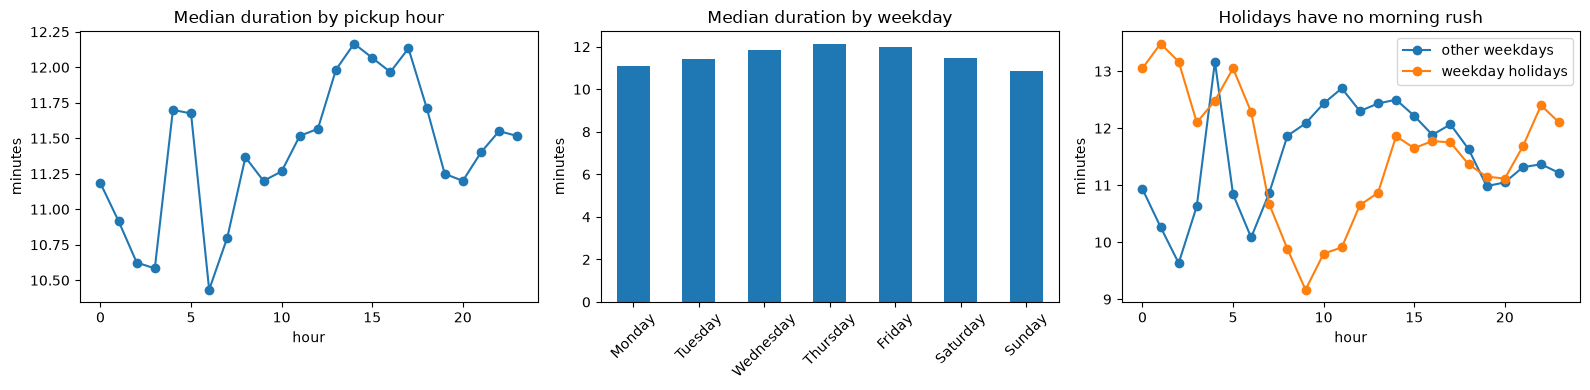

In [26]:
train_trips = jan.loc[tr]
pickup_tr = train_trips["tpep_pickup_datetime"]
is_holiday = pickup_tr.dt.date.isin(holiday_dates)
is_weekday = pickup_tr.dt.day_of_week < 5

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Median duration by pickup hour
by_hour.plot(ax=axes[0], marker="o")
axes[0].set(title="Median duration by pickup hour", xlabel="hour", ylabel="minutes")

# 2. Median duration by weekday
by_weekday.plot.bar(ax=axes[1], color="tab:blue")
axes[1].set(title="Median duration by weekday", xlabel="", ylabel="minutes")
axes[1].tick_params(axis="x", rotation=45)

# 3. Weekday holidays vs other weekdays, by hour
for label, mask, color in [("other weekdays", is_weekday & ~is_holiday, "tab:blue"),
                           ("weekday holidays", is_weekday & is_holiday, "tab:orange")]:
    (train_trips.loc[mask].groupby(pickup_tr[mask].dt.hour)["duration"].median()
     .plot(ax=axes[2], marker="o", label=label, color=color))
axes[2].set(title="Holidays have no morning rush", xlabel="hour", ylabel="minutes")
axes[2].legend()

plt.tight_layout()
plt.show()

del train_trips, pickup_tr, is_holiday, is_weekday  # free memory

- **Hour (left):** the median ranges from 10.4 min (6 am) to 12.2 min (2 pm).
- **Weekday (middle):** Thursday and Friday are slowest (12.1 / 12.0 min), Sunday fastest (10.8 min).
- **Holidays (right):** no morning rush: 9.4 vs 12.0 min at 8–10 am, and fewer trips: 88,445 per day on weekday holidays vs 110,440 on other weekdays (median).

→ **Decision: use pickup hour, weekday and a holiday flag as features.**

## 5. Features (shared with the API: `src/features.py`)

The same `build_features()` is used in training and in the API, so the features cannot differ between them.

| Feature | Source |
|---|---|
| `PULocationID`, `DOLocationID` | request |
| `hour`, `day_of_week`, `is_holiday` | pickup time (US federal holidays) |
| `PU_lat`, `PU_lon`, `DO_lat`, `DO_lon` | center of the TLC zone shape |
| `straight_dist` | miles between the two zone centers |

**Leakage check.** Every feature is known at pickup time. `trip_distance`, fares and drop-off time are
not used. The zone table (`zone_xy`) is fixed geography from the TLC shapefile, not learned from trips,
and there are **no target statistics** (such as zone-pair mean durations) in the features. Zones
without a shape (264 "Unknown", 265 "Outside NYC") get `-1`.

In [ ]:
zone_xy = build_zone_xy(ROOT / "data")  # downloads the zone shapefile on first use
X = build_features(jan, zone_xy)
assert list(X.columns) == FEATURES

# Feature availability: share of trips with an unknown zone (features set to -1), per split
print((X["straight_dist"] == -1).groupby(split).mean().map("{:.2%}".format).to_string())
X.head()

test          0.70%
train         0.76%
validation    0.66%


,PULocationID,DOLocationID,hour,day_of_week,is_holiday,PU_lat,PU_lon,DO_lat,DO_lon,straight_dist
2,237,262,0,2,1,40.768615,-73.965635,40.775932,-73.946510,1.123119
3,107,114,0,2,1,40.736824,-73.984052,40.728340,-73.997380,0.912192
4,148,45,0,2,1,40.718938,-73.990896,40.712459,-73.998151,0.587335
5,148,45,0,2,1,40.718938,-73.990896,40.712459,-73.998151,0.587335
6,132,10,0,2,1,40.646985,-73.786530,40.678953,-73.790987,2.218236


Every split has the same 10 features, and only a small share of trips has an unknown zone
(train 0.76%, validation 0.66%, test 0.70%), so missing locations hardly affect the model.

## What the exploration decides

| Finding | Decision |
|---|---|
| 97.9% of trips last 1–60 minutes; the rest are mostly recording errors | Keep trips of 1–60 minutes |
| Trips over 1 hour are rare (0.9%) | Model and API cover trips up to 60 minutes |
| Fare, tip and total are only known after the trip | Never used as features |
| The driven distance is only known after the trip | Distance comes from zone centers |
| Duration changes with the hour and weekday | Add hour and weekday features |
| Holidays have no morning rush | Add a holiday feature |
| Predictions are always for future days | Split by date: train Jan 1–20, validation Jan 21–25, test Jan 26–31 |

**Next step:** `uv run nyc-taxi all` trains, compares and registers the models.

In [ ]:
import mlflow
from sklearn.metrics import root_mean_squared_error

from src.experiment import MODEL_NAME, TRACKING_URI

VERSION = 1          # the served model
N_TRIPS = 100_000    # validation trips used
N_REPEATS = 3        # shuffles per feature, averaged

mlflow.set_tracking_uri(TRACKING_URI)
model = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}/{VERSION}")

sample = X[va].sample(n=N_TRIPS, random_state=42)
X_val, y_val = sample, jan.loc[sample.index, "duration"].to_numpy()
base_rmse = root_mean_squared_error(y_val, model.predict(X_val))
rng = np.random.default_rng(42)


def rmse_increase(columns):
    """Average RMSE increase when the given columns are shuffled together."""
    increases = []
    for _ in range(N_REPEATS):
        X_shuffled = X_val.copy()
        X_shuffled[columns] = X_shuffled[columns].to_numpy()[rng.permutation(len(X_shuffled))]
        increases.append(root_mean_squared_error(y_val, model.predict(X_shuffled)) - base_rmse)
    return float(np.mean(increases))


single = pd.DataFrame({
    "weight": model.feature_importances_,
    "rmse_increase": [rmse_increase([f]) for f in FEATURES],
}, index=FEATURES).sort_values("rmse_increase", ascending=False)
single["weight"] = single["weight"].map("{:.1%}".format)
print(f"Validation RMSE of version {VERSION}: {base_rmse:.3f} min\n")
print(single.round(3).to_string())

groups = {
    "zone IDs": ["PULocationID", "DOLocationID"],
    "location (coordinates + distance)": ["PU_lat", "PU_lon", "DO_lat", "DO_lon", "straight_dist"],
    "time (hour + weekday + holiday)": ["hour", "day_of_week", "is_holiday"],
}
grouped = pd.Series({name: rmse_increase(cols) for name, cols in groups.items()})
print("\nRMSE increase when a whole group is shuffled:")
print(grouped.sort_values(ascending=False).round(3).to_string())

NameError: name 'X' is not defined

In [ ]:
from src.train import load_january, split_by_time

jan = load_january()
_, va, _ = split_by_time(jan)
val = jan[va].sample(n=N_TRIPS, random_state=42)
X_val = build_features(val, build_zone_xy(ROOT / "data"))
y_val = val["duration"].to_numpy()
base_rmse = root_mean_squared_error(y_val, model.predict(X_val))
rng = np.random.default_rng(42)

1 a7b48723d8ff43c0865fe4aaf694bde4 []


In [10]:
  client = mlflow.MlflowClient()
  VERSION = max(int(mv.version) for mv in client.search_model_versions(f"name='{MODEL_NAME}'"))
  print("Using version", VERSION)

Using version 1


In [11]:
mv = mlflow.MlflowClient().get_model_version(MODEL_NAME, "1")
run = mlflow.get_run(mv.run_id)
print(run.info.run_name, run.data.params.get("winner"), run.data.metrics.get("winner_val_rmse"))

select trial-1 4.44351878518243
